# Resultados do SVM diário: relatório visual comentado

Este notebook lê a execução salva **daily_full_01**, o último processamento identificado na criação do relatório. A execução fica explícita para que a análise não mude silenciosamente para outro experimento.

Execute as células em ordem no ambiente Python do projeto (`python -m pip install -e '.[dev]'`). A leitura valida os arquivos e a integridade das suas fontes. Nenhuma coleta, construção de variáveis ou etapa de treinamento é executada aqui.

Cada gráfico tem sua seleção de dados, agregação e construção nas próprias células deste notebook. As funções auxiliares abaixo apenas padronizam a apresentação. As figuras descrevem **classificação**, não rentabilidade. Resultados de treino são retrospectivos; a validação fora da amostra fornece evidência sobre generalização.

In [1]:
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from tcc_crypto import experiment
from tcc_crypto.paths import ROOT, Paths

## 1. Carregar a execução e conferir a origem

A validação de integridade pode levar alguns instantes. O resumo distingue o universo configurado dos ativos que efetivamente possuem métricas. Nomes de arquivos, colunas e identificadores técnicos permanecem em inglês para corresponder aos dados salvos.

In [2]:
paths = Paths(ROOT, "full_01")
report = experiment.load_report(paths)
study = report["configuration"]["experiment"]["study"]
summary = {
    "Execução": report["run_id"],
    "Início da execução (UTC)": report["execution"]["execution_time_utc"],
    "Revisão do código": report["execution"].get("revision"),
    "Período do estudo": f"{study['start']} a {study['end']} UTC",
    "Ativos configurados": len(report["configuration"]["experiment"]["symbols"]),
    "Ativos com métricas": report["tables"]["metrics"]["symbol"].nunique(),
    "Combinações de alvo e janela": report["tables"]["metrics"][
        ["target", "window_size"]
    ]
    .drop_duplicates()
    .values.tolist(),
}
display(pd.DataFrame(summary.items(), columns=["Informação", "Valor salvo"]))

,Informação,Valor salvo
0,Execução,full_01
1,Início da execução (UTC),2026-11-01T19:51:16.449231+00:00
2,Revisão do código,0a9d52bb055f9b5b90c1ff04e42d4ad4b4a05425
3,Período do estudo,2019-07-01 a 2026-09-01 UTC
4,Ativos configurados,40
5,Ativos com métricas,39
6,Combinações de alvo e janela,"[[target_1pct, 60], [target_2pct, 60], [target..."


## 2. Escolher o alvo e o tamanho da janela

São filtros de visualização, não novos parâmetros do experimento. As combinações disponíveis aparecem no resumo acima. Altere os filtros e execute novamente esta célula e as seguintes. O ativo escolhido é usado apenas na linha do tempo. Alvos e tamanhos de janela diferentes nunca são misturados.

In [3]:
target = "target_1pct"
window_size = 60
symbol = "BTCUSDT"

# Filtrar cada tabela, preservando valores ausentes e a configuração da execução.
tables = {}
for name, frame in report["tables"].items():
    if "target" in frame:
        frame = frame.loc[
            frame["target"].eq(target) & frame["window_size"].eq(window_size)
        ]
    tables[name] = frame.copy()
metrics = tables["metrics"]
if metrics.empty:
    raise ValueError(f"Não há métricas salvas para {target}, janela={window_size}.")
roles = ("in_sample", "out_of_sample")
role_labels = {"in_sample": "Treino", "out_of_sample": "Validação"}

### Apresentação comum dos gráficos

Os auxiliares abaixo definem cores, orientação das barras e tratamento visual de ausências. Toda seleção e agregação específica permanece na célula de cada gráfico. Os identificadores técnicos dos dados são preservados; os rótulos exibidos são traduzidos.

In [4]:
labels = {
    "in_sample": "Treino",
    "out_of_sample": "Validação",
    "tuned_svc": "SVC ajustado",
    "default_svc": "SVC padrão",
    "always_negative": "Sempre negativo",
    "training_class_frequency": "Frequência da classe no treino",
    "evaluated_count": "Avaliadas",
    "omitted_count": "Omitidas",
    "observed": "Observado",
    "filled": "Preenchido",
    "imputed": "Preenchido",
    "retained": "Mantida",
    "high_correlation": "Alta correlação",
    "low_variance": "Baixa variância",
    "no_common_predictions": "Sem previsões em datas comuns",
    "missing_candle": "Candle ausente",
    "ok": "Concluído",
    "symbol": "Ativo",
    "model": "Modelo",
    "feature": "Variável",
    "reason": "Motivo",
    "status": "Situação",
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1",
    "balanced_accuracy": "Balanced Accuracy",
    "roc_auc": "ROC-AUC",
    "average_precision": "Average Precision",
}


def bars(table, ax, title, ylabel):
    """Padronizar as barras sem alterar os valores calculados na célula do gráfico."""
    table = table.rename(index=labels, columns=labels).rename_axis(
        index=labels.get(table.index.name, table.index.name),
        columns=labels.get(table.columns.name, table.columns.name),
    )
    if table.empty or table.dropna(how="all").empty:
        ax.text(0.5, 0.5, "Sem observações disponíveis", ha="center")
        ax.set_axis_off()
        return
    if len(table) > 15:
        ax.figure.set_figheight(max(10, len(table) * 0.28))
        table.plot.barh(ax=ax)
        ax.set_xlabel(ylabel)
        ax.grid(axis="x", alpha=0.2)
    else:
        table.plot.bar(ax=ax, rot=30)
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", alpha=0.2)
    ax.set_title(title)


def heatmap(table, ax, title, *, binary=False):
    """Exibir valores binários e destacar ausências em rosa."""
    if table.empty:
        ax.text(0.5, 0.5, "Sem observações disponíveis", ha="center")
        return
    cmap = (
        ListedColormap(["#e5e7eb", "#2563eb"])
        if binary
        else plt.get_cmap("YlGnBu").copy()
    )
    cmap.set_bad("#ef9a9a")
    im = ax.imshow(
        table.to_numpy(dtype=float, na_value=np.nan),
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        vmin=0,
        vmax=1,
    )
    ax.set_yticks(range(len(table)), table.index)
    ticks = np.unique(
        np.linspace(0, len(table.columns) - 1, min(5, len(table.columns))).astype(int)
    )
    ax.set_xticks(ticks, [str(table.columns[i])[:10] for i in ticks], rotation=30)
    ax.set_title(title)
    ax.figure.colorbar(im, ax=ax, shrink=0.7, label="Fração / valor binário")

## Disponibilidade dos dados brutos

Azul indica candle diário válido; cinza indica ausência; rosa indica informação desconhecida. As barras mostram a fração das datas inspecionadas com dados disponíveis. Listagens recentes naturalmente têm históricos menores. Disponibilidade, isoladamente, não determina elegibilidade para o modelo.

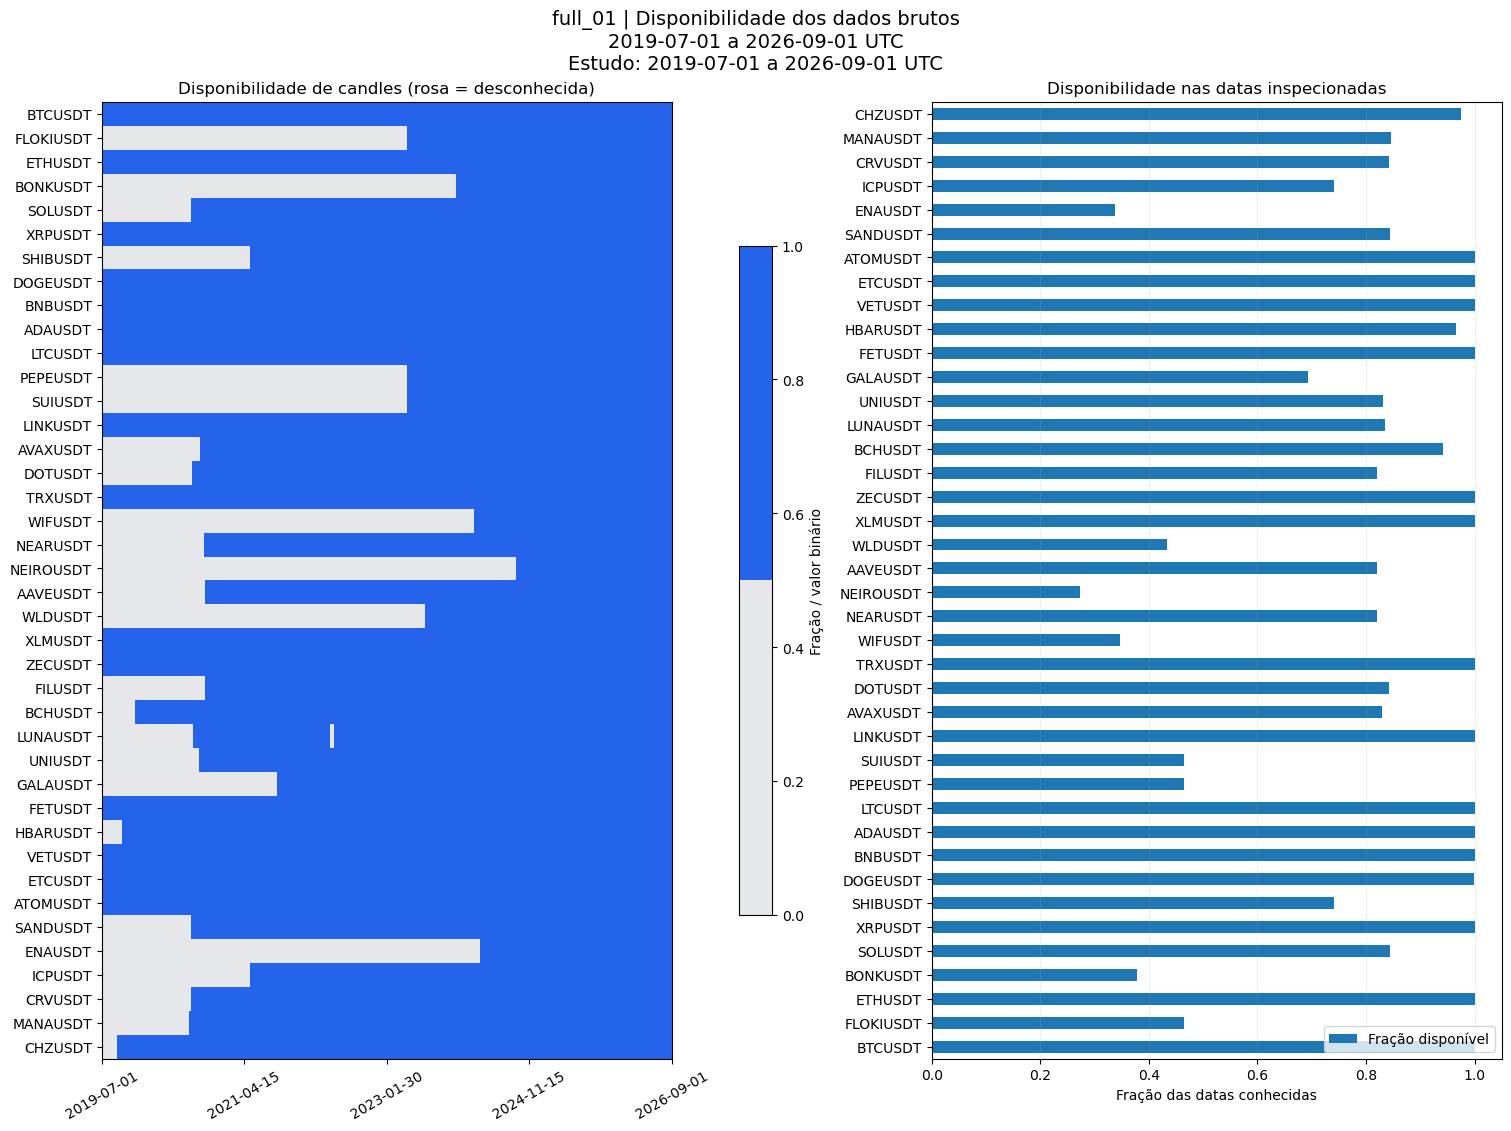

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
frame = report["tables"]["availability"].set_index("date_utc")
heatmap(
    frame.T, axes[0], "Disponibilidade de candles (rosa = desconhecida)", binary=True
)
bars(
    frame.mean().to_frame("Fração disponível"),
    axes[1],
    "Disponibilidade nas datas inspecionadas",
    "Fração das datas conhecidas",
)
subtitle = f"{frame.index.min():%Y-%m-%d} a {frame.index.max():%Y-%m-%d} UTC"
fig.suptitle(
    f"{report['run_id']} | Disponibilidade dos dados brutos\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Tratamento dos dados e preenchimento

O painel esquerdo conta os registros por situação, incluindo o período de aquecimento dos indicadores. O painel direito conta somente os registros preenchidos, separados por motivo. Um painel vazio indica ausência de preenchimentos registrados. Considere os diferentes comprimentos de histórico ao comparar contagens.

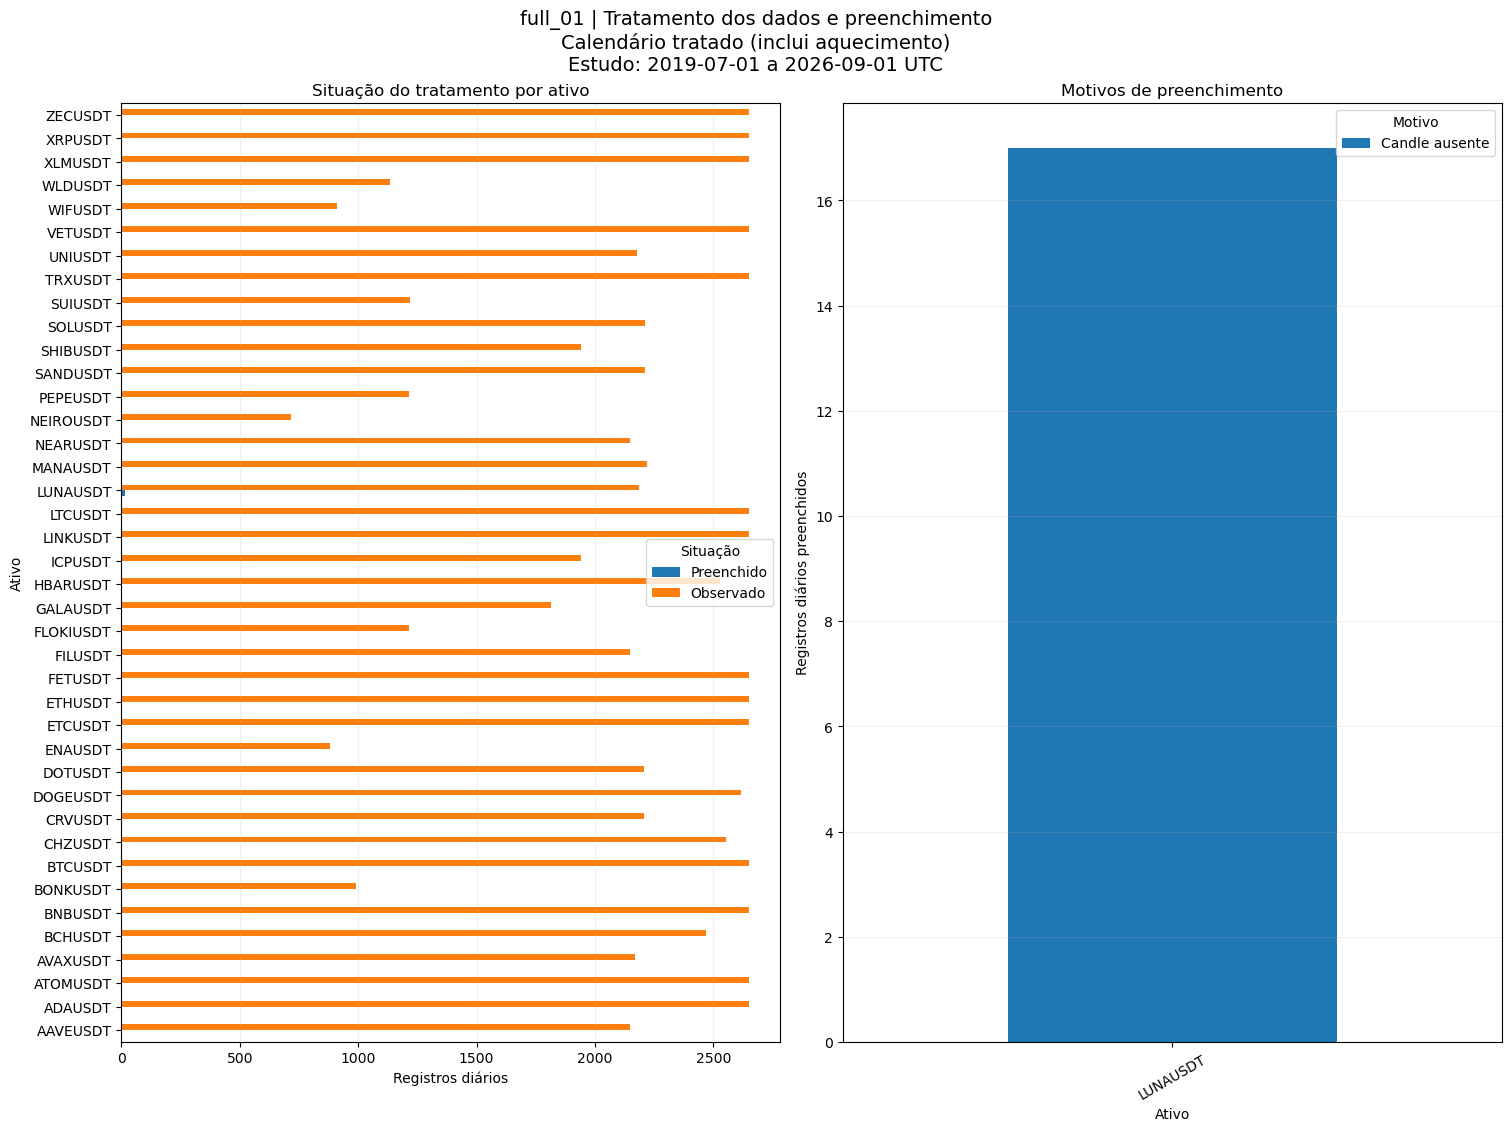

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
frame = report["tables"]["treatment"]
bars(
    pd.crosstab(frame.symbol, frame.status),
    axes[0],
    "Situação do tratamento por ativo",
    "Registros diários",
)
filled = frame.loc[frame.is_imputed.fillna(False)]
bars(
    pd.crosstab(filled.symbol, filled.reason),
    axes[1],
    "Motivos de preenchimento",
    "Registros diários preenchidos",
)
subtitle = "Calendário tratado (inclui aquecimento)"
fig.suptitle(
    f"{report['run_id']} | Tratamento dos dados e preenchimento\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Observações avaliadas e omitidas

As contagens são somadas nos blocos, separadamente por modelo e por etapa. Avaliadas mais omitidas correspondem às tentativas. São contagens de observações por modelo, não de dias únicos de mercado entre ativos. Leia as omissões junto com as métricas.

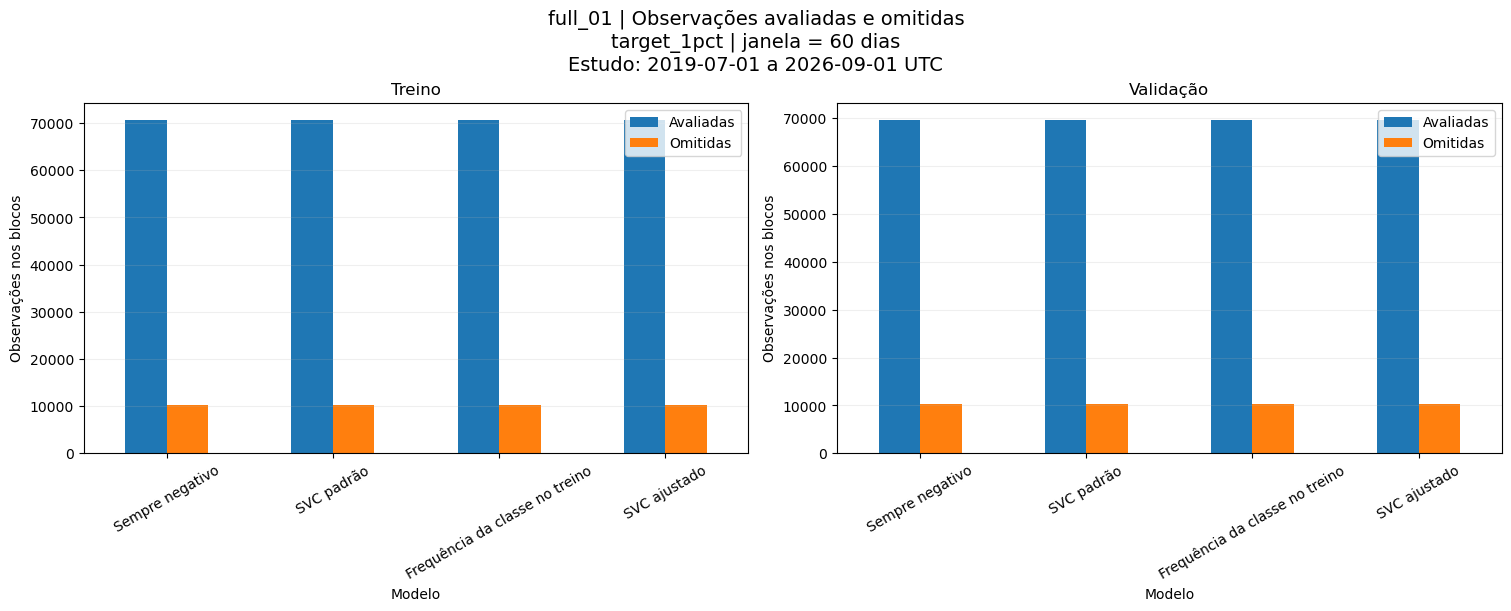

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role)]
    bars(
        rows.groupby("model")[["evaluated_count", "omitted_count"]].sum(),
        ax,
        role_labels[role],
        "Observações nos blocos",
    )
fig.suptitle(
    f"{report['run_id']} | Observações avaliadas e omitidas\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Situação da avaliação

Cada unidade representa um registro de métricas de um modelo em um bloco. As situações revelam avaliações indisponíveis ou restritas. Resultado ausente não equivale a pontuação zero.

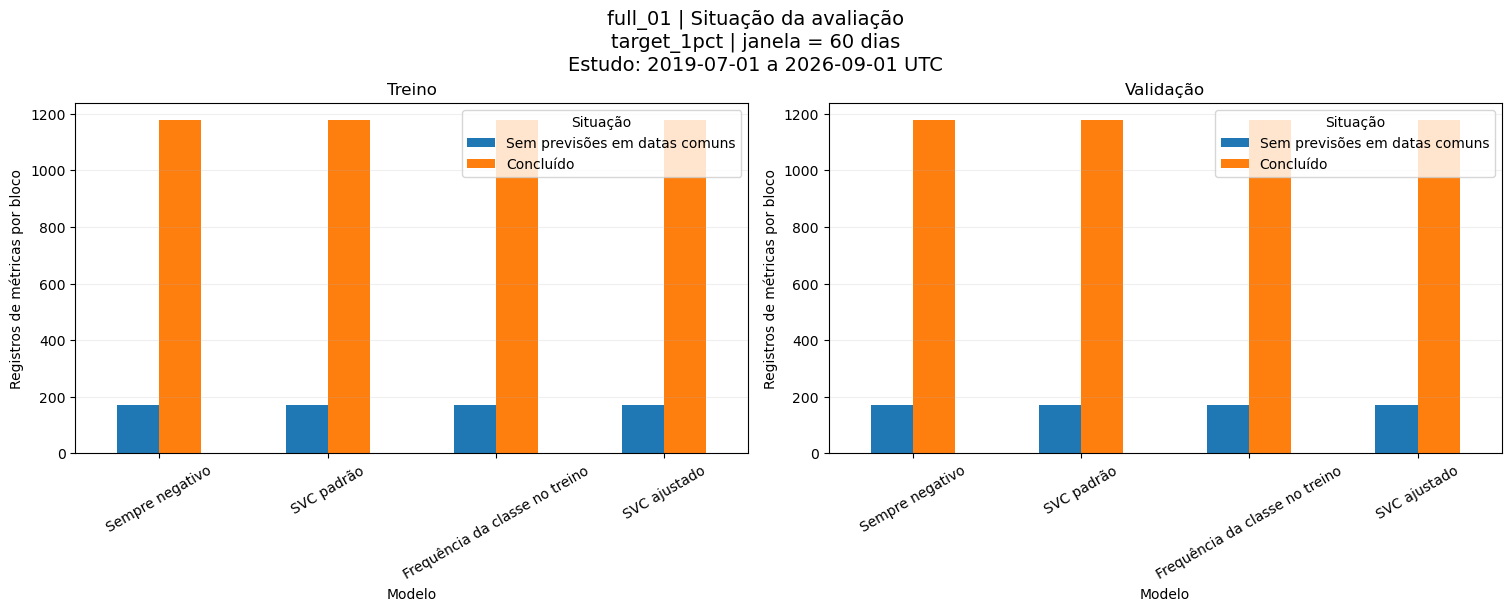

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role)]
    bars(
        pd.crosstab(rows.model, rows.status),
        ax,
        role_labels[role],
        "Registros de métricas por bloco",
    )
fig.suptitle(
    f"{report['run_id']} | Situação da avaliação\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Métricas de classificação: comparação dos modelos

Cada barra representa a **média não ponderada das pontuações disponíveis por ativo e bloco**. `n` informa quantas pontuações estão definidas. É um resumo descritivo, não uma métrica calculada sobre todas as previsões agrupadas nem um teste de significância. Ativos com mais blocos contribuem mais para essa média. O número de resultados válidos pode variar entre métricas.

### Accuracy

Fração das previsões avaliadas que estão corretas. Uma classe muito frequente pode produzir accuracy elevada mesmo com um classificador pouco informativo.

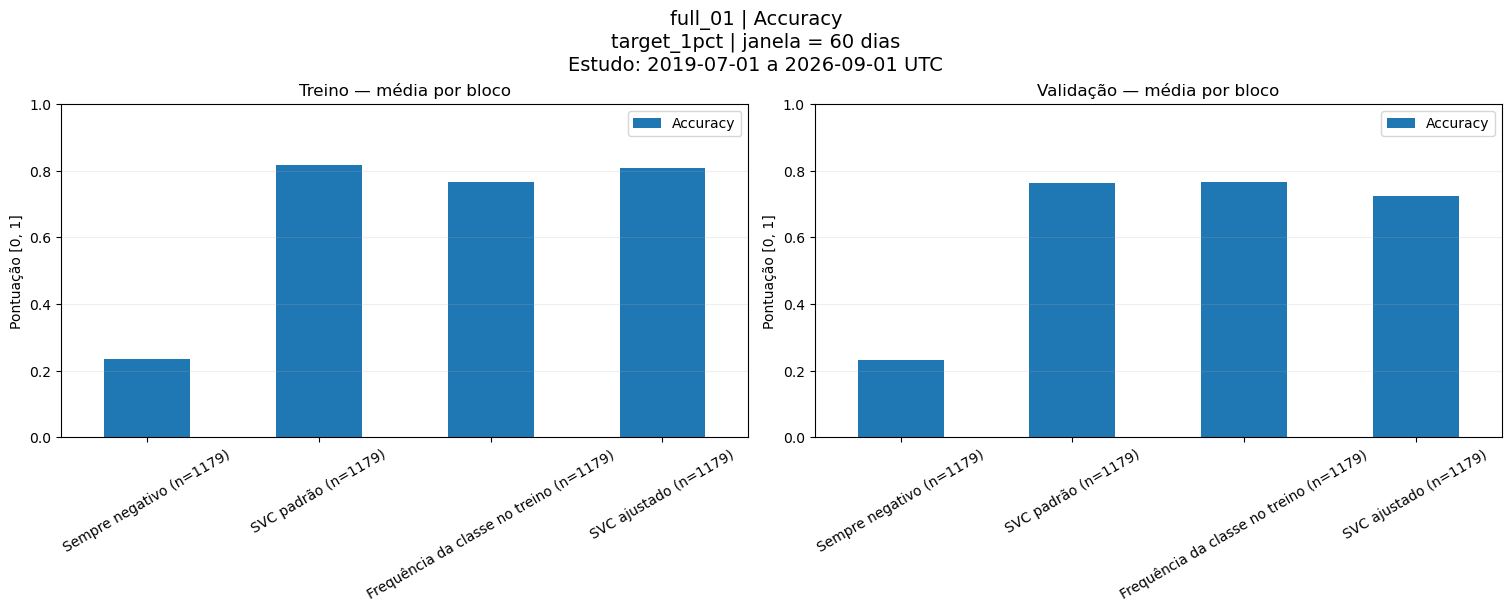

In [9]:
metric = "accuracy"
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
allowed = {
    "accuracy",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "roc_auc",
    "average_precision",
}
if metric not in allowed:
    raise ValueError(f"Métrica desconhecida: {metric}")
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role)]
    grouped = rows.groupby("model")[metric]
    table = grouped.mean().to_frame(metric)
    table.index = [
        f"{labels.get(model, model)} (n={grouped.count()[model]})"
        for model in table.index
    ]
    bars(table, ax, role_labels[role] + " — média por bloco", "Pontuação [0, 1]")
    ax.set_ylim(0, 1)
fig.suptitle(
    f"{report['run_id']} | Accuracy\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

### Precision

Entre as previsões positivas, fração que realmente pertence à classe positiva. Interprete junto com a recall e a frequência dos sinais.

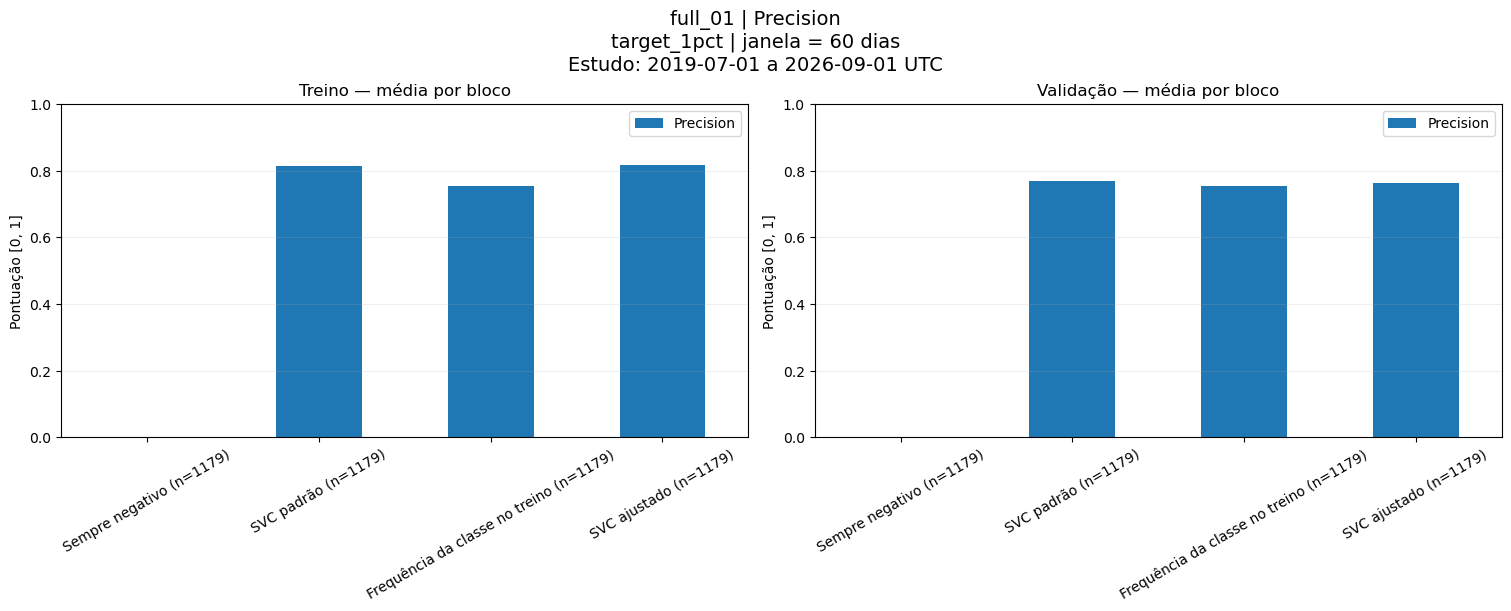

In [10]:
metric = "precision"
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
allowed = {
    "accuracy",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "roc_auc",
    "average_precision",
}
if metric not in allowed:
    raise ValueError(f"Métrica desconhecida: {metric}")
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role)]
    grouped = rows.groupby("model")[metric]
    table = grouped.mean().to_frame(metric)
    table.index = [
        f"{labels.get(model, model)} (n={grouped.count()[model]})"
        for model in table.index
    ]
    bars(table, ax, role_labels[role] + " — média por bloco", "Pontuação [0, 1]")
    ax.set_ylim(0, 1)
fig.suptitle(
    f"{report['run_id']} | Precision\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

### Recall

Entre os casos realmente positivos, fração detectada pelo classificador.

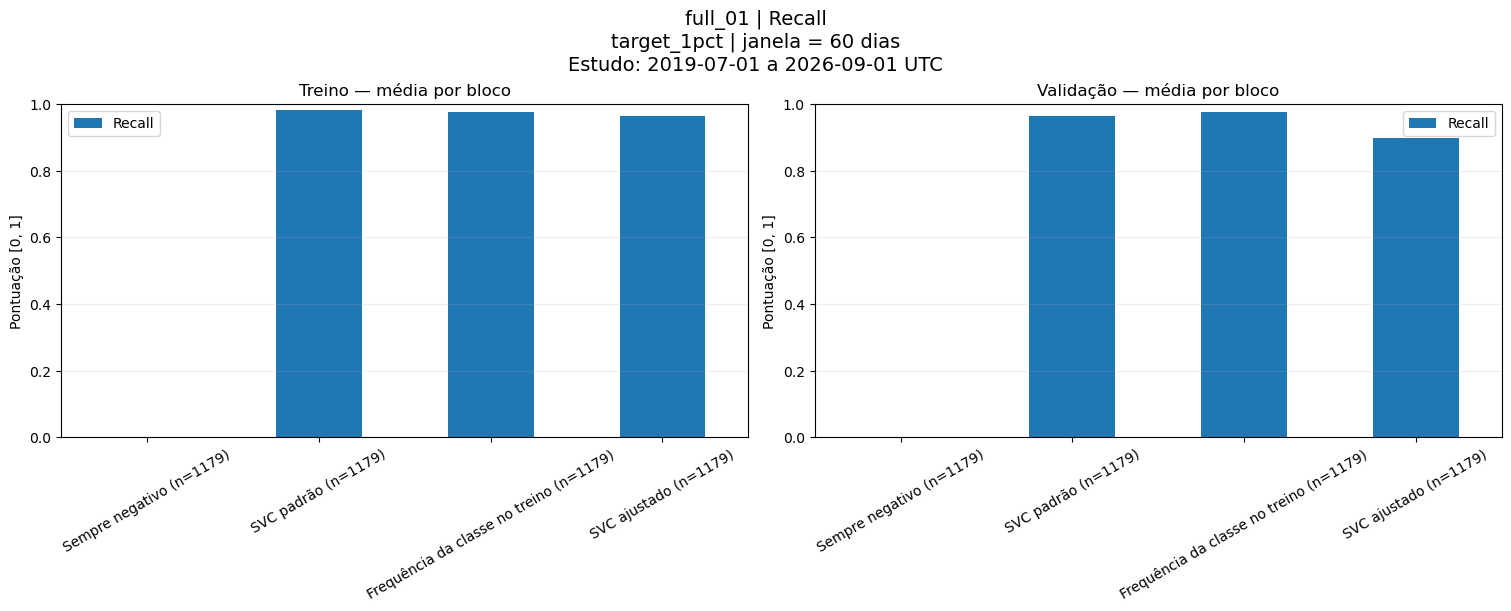

In [11]:
metric = "recall"
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
allowed = {
    "accuracy",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "roc_auc",
    "average_precision",
}
if metric not in allowed:
    raise ValueError(f"Métrica desconhecida: {metric}")
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role)]
    grouped = rows.groupby("model")[metric]
    table = grouped.mean().to_frame(metric)
    table.index = [
        f"{labels.get(model, model)} (n={grouped.count()[model]})"
        for model in table.index
    ]
    bars(table, ax, role_labels[role] + " — média por bloco", "Pontuação [0, 1]")
    ax.set_ylim(0, 1)
fig.suptitle(
    f"{report['run_id']} | Recall\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

### F1

Média harmônica da precision e da recall. Valores elevados exigem bom desempenho nas duas medidas.

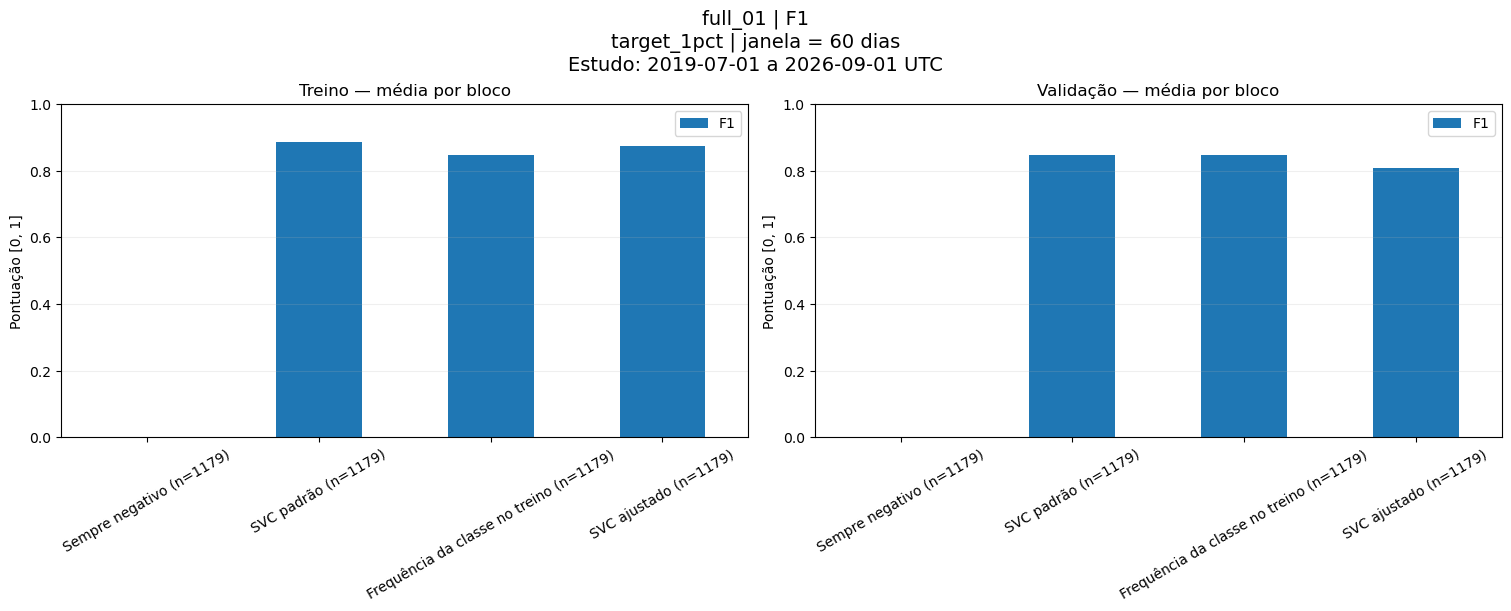

In [12]:
metric = "f1"
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
allowed = {
    "accuracy",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "roc_auc",
    "average_precision",
}
if metric not in allowed:
    raise ValueError(f"Métrica desconhecida: {metric}")
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role)]
    grouped = rows.groupby("model")[metric]
    table = grouped.mean().to_frame(metric)
    table.index = [
        f"{labels.get(model, model)} (n={grouped.count()[model]})"
        for model in table.index
    ]
    bars(table, ax, role_labels[role] + " — média por bloco", "Pontuação [0, 1]")
    ax.set_ylim(0, 1)
fig.suptitle(
    f"{report['run_id']} | F1\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

### Balanced Accuracy

Média da recall das classes, conforme definida na avaliação salva. Verifique os diagnósticos de janelas que contêm apenas uma classe.

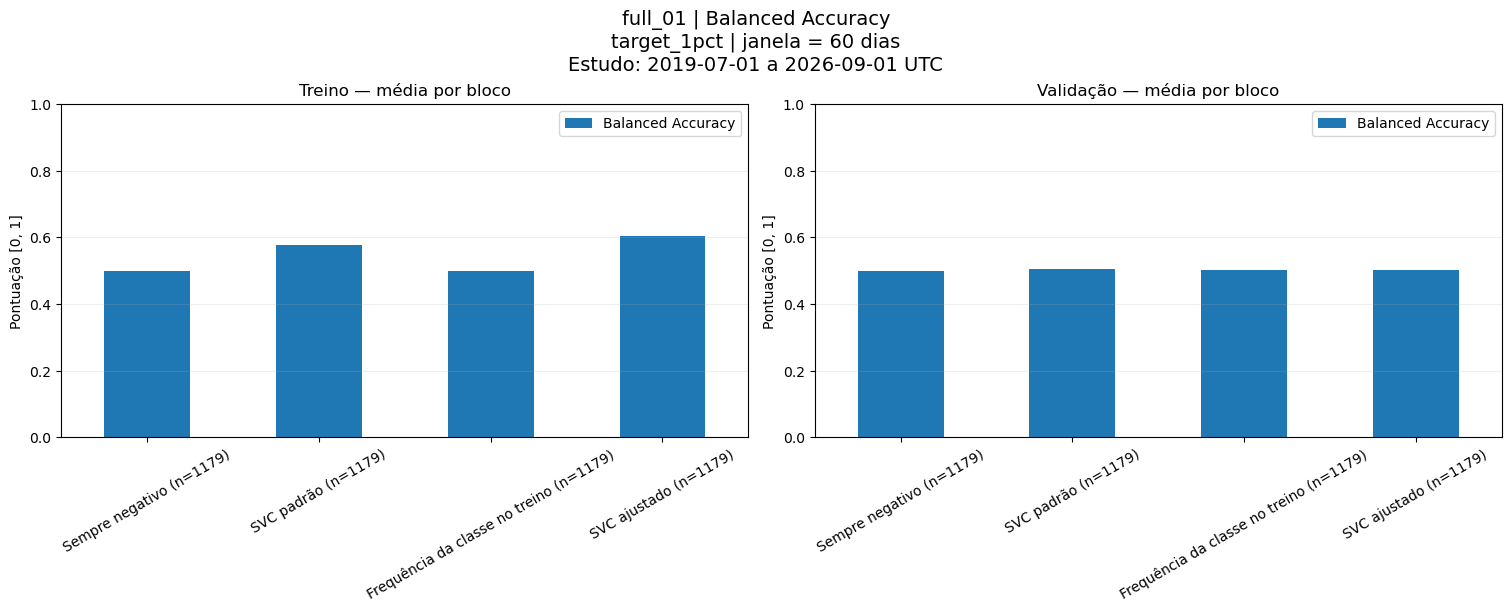

In [13]:
metric = "balanced_accuracy"
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
allowed = {
    "accuracy",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "roc_auc",
    "average_precision",
}
if metric not in allowed:
    raise ValueError(f"Métrica desconhecida: {metric}")
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role)]
    grouped = rows.groupby("model")[metric]
    table = grouped.mean().to_frame(metric)
    table.index = [
        f"{labels.get(model, model)} (n={grouped.count()[model]})"
        for model in table.index
    ]
    bars(table, ax, role_labels[role] + " — média por bloco", "Pontuação [0, 1]")
    ax.set_ylim(0, 1)
fig.suptitle(
    f"{report['run_id']} | Balanced Accuracy\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

### ROC-AUC

Mede a discriminação do ordenamento ao variar o limiar de classificação. Pode ser indefinida quando há apenas uma classe observada. Valores ausentes são excluídos da média, nunca substituídos por zero.

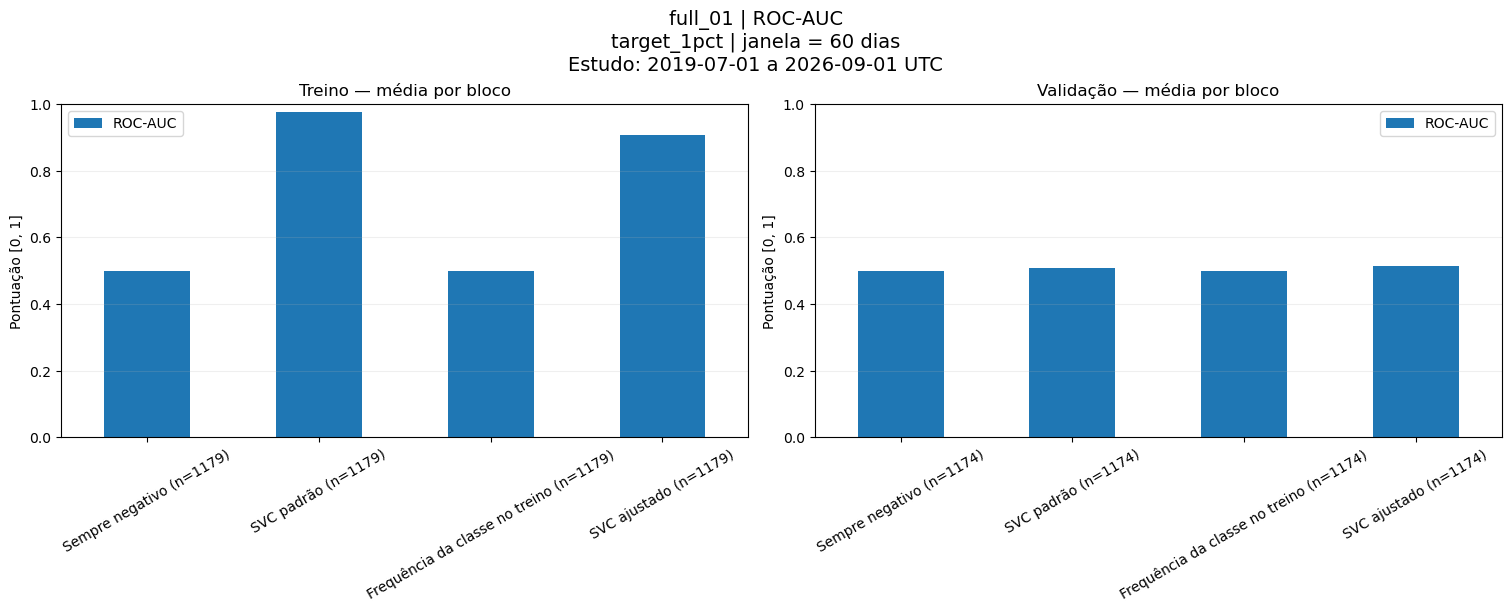

In [14]:
metric = "roc_auc"
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
allowed = {
    "accuracy",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "roc_auc",
    "average_precision",
}
if metric not in allowed:
    raise ValueError(f"Métrica desconhecida: {metric}")
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role)]
    grouped = rows.groupby("model")[metric]
    table = grouped.mean().to_frame(metric)
    table.index = [
        f"{labels.get(model, model)} (n={grouped.count()[model]})"
        for model in table.index
    ]
    bars(table, ax, role_labels[role] + " — média por bloco", "Pontuação [0, 1]")
    ax.set_ylim(0, 1)
fig.suptitle(
    f"{report['run_id']} | ROC-AUC\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

### Average Precision

Resume a relação entre precision e recall ao longo do ordenamento. Depende da prevalência da classe positiva; consulte também o equilíbrio das classes.

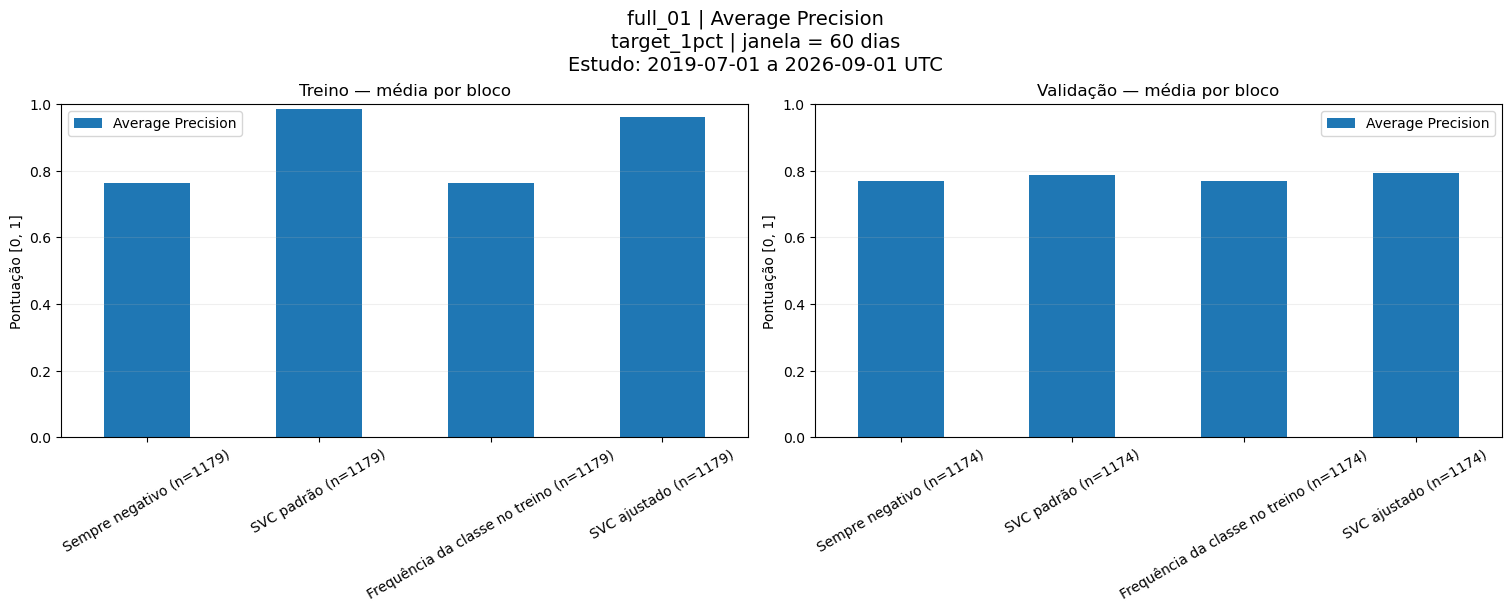

In [15]:
metric = "average_precision"
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
allowed = {
    "accuracy",
    "precision",
    "recall",
    "f1",
    "balanced_accuracy",
    "roc_auc",
    "average_precision",
}
if metric not in allowed:
    raise ValueError(f"Métrica desconhecida: {metric}")
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role)]
    grouped = rows.groupby("model")[metric]
    table = grouped.mean().to_frame(metric)
    table.index = [
        f"{labels.get(model, model)} (n={grouped.count()[model]})"
        for model in table.index
    ]
    bars(table, ax, role_labels[role] + " — média por bloco", "Pontuação [0, 1]")
    ax.set_ylim(0, 1)
fig.suptitle(
    f"{report['run_id']} | Average Precision\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Desempenho por ativo

F1 médio dos blocos de cada modelo e ativo, com treino e validação separados. Barras ausentes representam resultados indisponíveis. Históricos podem ter comprimentos diferentes; números de blocos de ativos distintos não representam necessariamente o mesmo período.

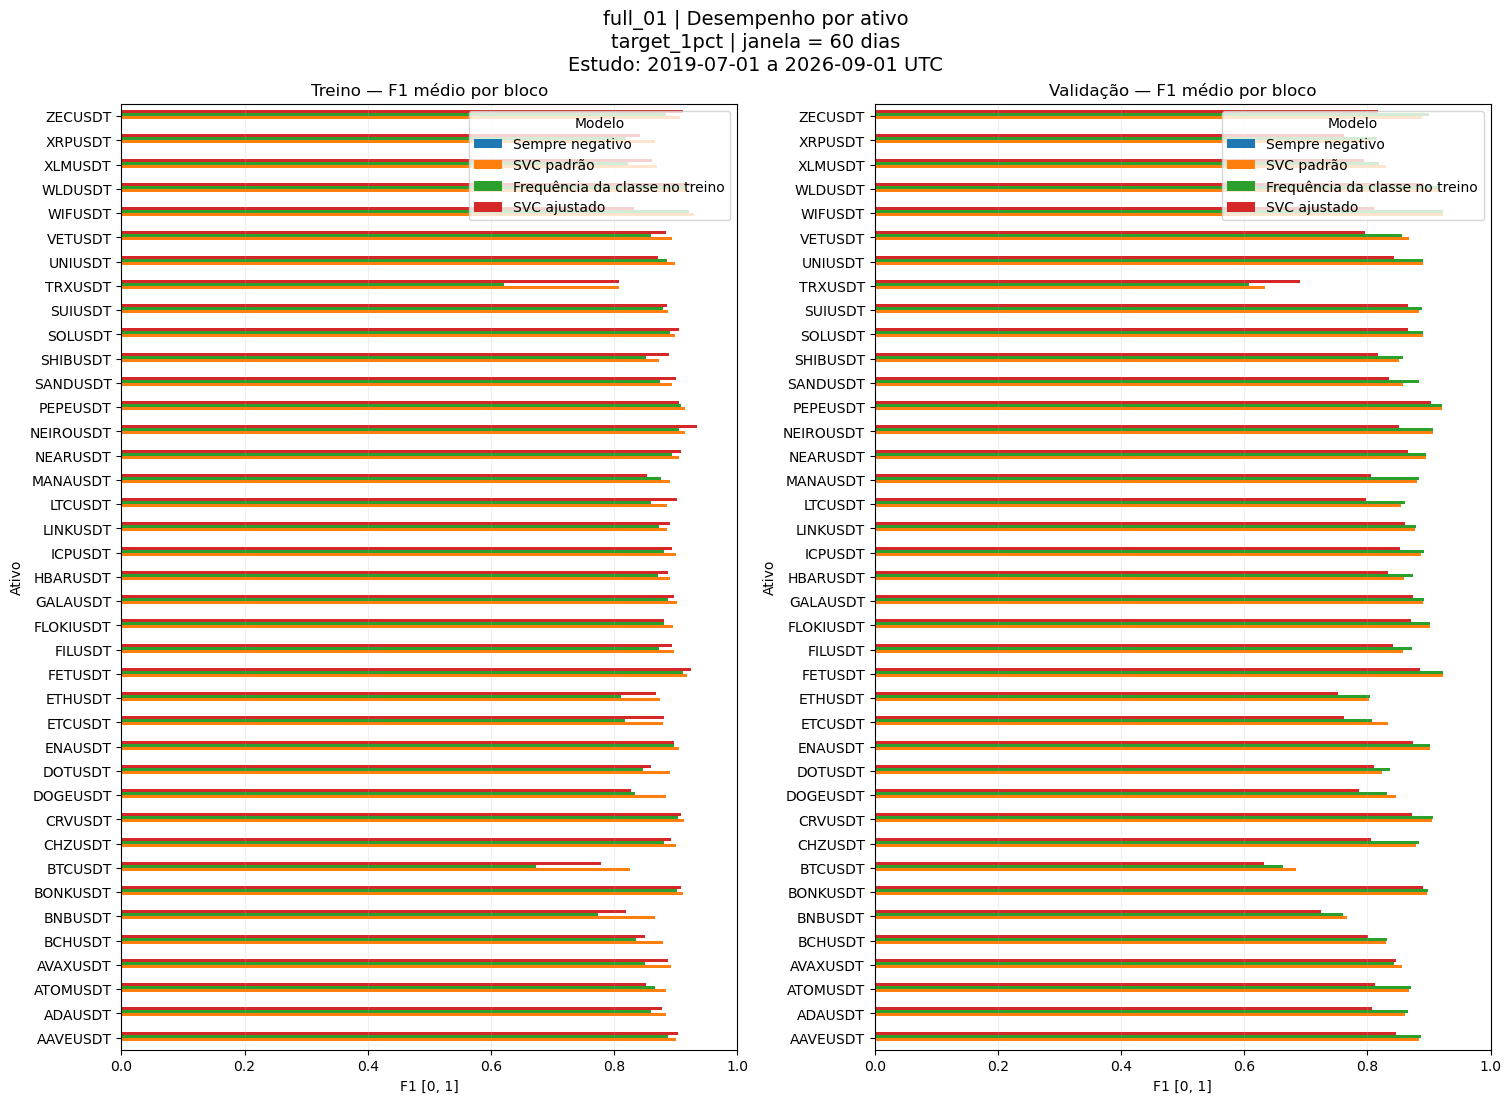

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role)]
    bars(
        rows.pivot_table(index="symbol", columns="model", values="f1", aggfunc="mean"),
        ax,
        role_labels[role] + " — F1 médio por bloco",
        "F1 [0, 1]",
    )
    ax.set_xlim(0, 1) if rows.symbol.nunique() > 15 else ax.set_ylim(0, 1)
fig.suptitle(
    f"{report['run_id']} | Desempenho por ativo\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Acertos e erros do SVC ajustado

Linhas representam a classe observada e colunas, a prevista. A célula superior direita contém falsos positivos; a inferior esquerda, falsos negativos. As contagens somam as avaliações salvas nas datas comuns aos modelos, para o SVC ajustado. Não há normalização para corrigir o desequilíbrio das classes.

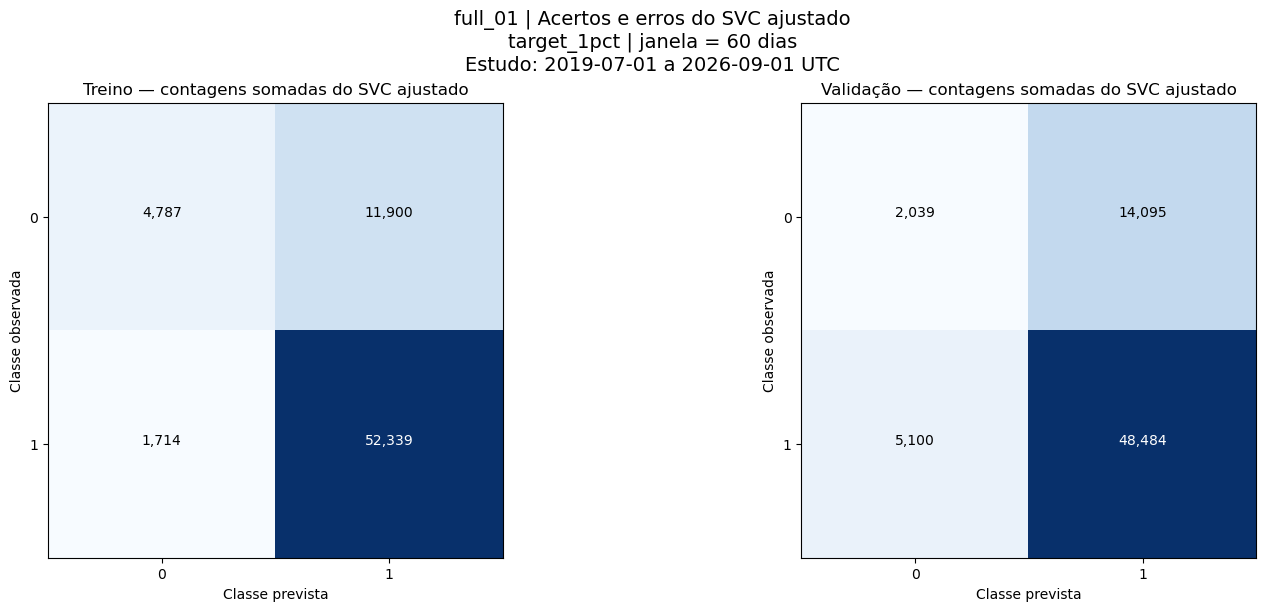

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
for ax, role in zip(axes, roles):
    rows = metrics.loc[metrics.role.eq(role) & metrics.model.eq("tuned_svc")]
    cols = ["true_negative", "false_positive", "false_negative", "true_positive"]
    counts = rows[cols].sum(min_count=1).to_numpy(dtype=float).reshape(2, 2)
    ax.imshow(counts, cmap="Blues")
    for (i, j), value in np.ndenumerate(counts):
        ax.text(
            j,
            i,
            f"{value:,.0f}" if np.isfinite(value) else "Indisponível",
            ha="center",
            color="white" if value > np.nanmax(counts) / 2 else "black",
        )
    ax.set(
        xticks=[0, 1],
        yticks=[0, 1],
        xlabel="Classe prevista",
        ylabel="Classe observada",
        title=role_labels[role] + " — contagens somadas do SVC ajustado",
    )
fig.suptitle(
    f"{report['run_id']} | Acertos e erros do SVC ajustado\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Distribuição das classes observadas

Fração dos rótulos disponíveis iguais a 1 por ativo. Cada etapa usa sua própria matriz salva. A classe positiva representa o alvo configurado para o dia seguinte, não rentabilidade de uma carteira.

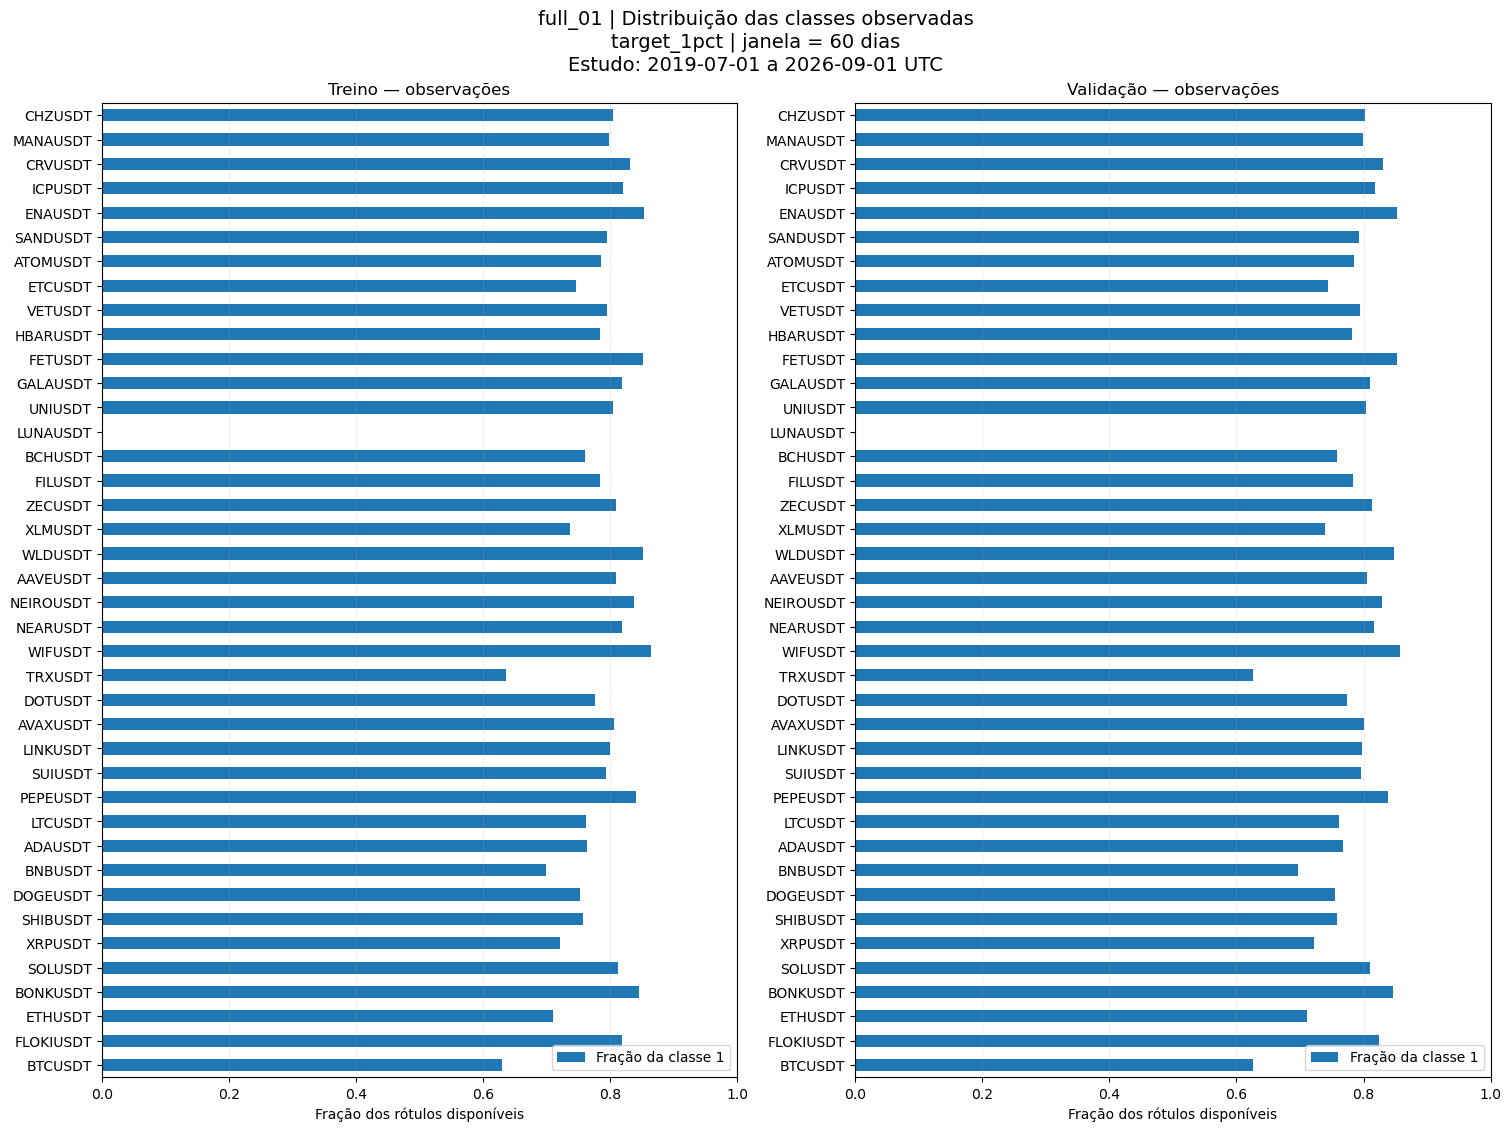

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
for ax, role in zip(axes, roles):
    prefix = "actuals_"
    rows = tables[prefix + role].copy()
    table = rows.drop(columns=["target", "window_size"]).set_index("feature_time_utc")
    bars(
        pd.DataFrame({"Fração da classe 1": table.mean()}),
        ax,
        role_labels[role]
        + (" — previsões" if prefix == "predictions_" else " — observações"),
        "Fração dos rótulos disponíveis",
    )
    ax.set_xlim(0, 1) if len(table.columns) > 15 else ax.set_ylim(0, 1)
fig.suptitle(
    f"{report['run_id']} | Distribuição das classes observadas\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Frequência dos sinais positivos do SVC

Fração das previsões disponíveis do SVC ajustado iguais a 1. Previsões ausentes são excluídas. Pode haver rótulo observado em uma data sem previsão, portanto os denominadores podem diferir dos usados na distribuição das classes.

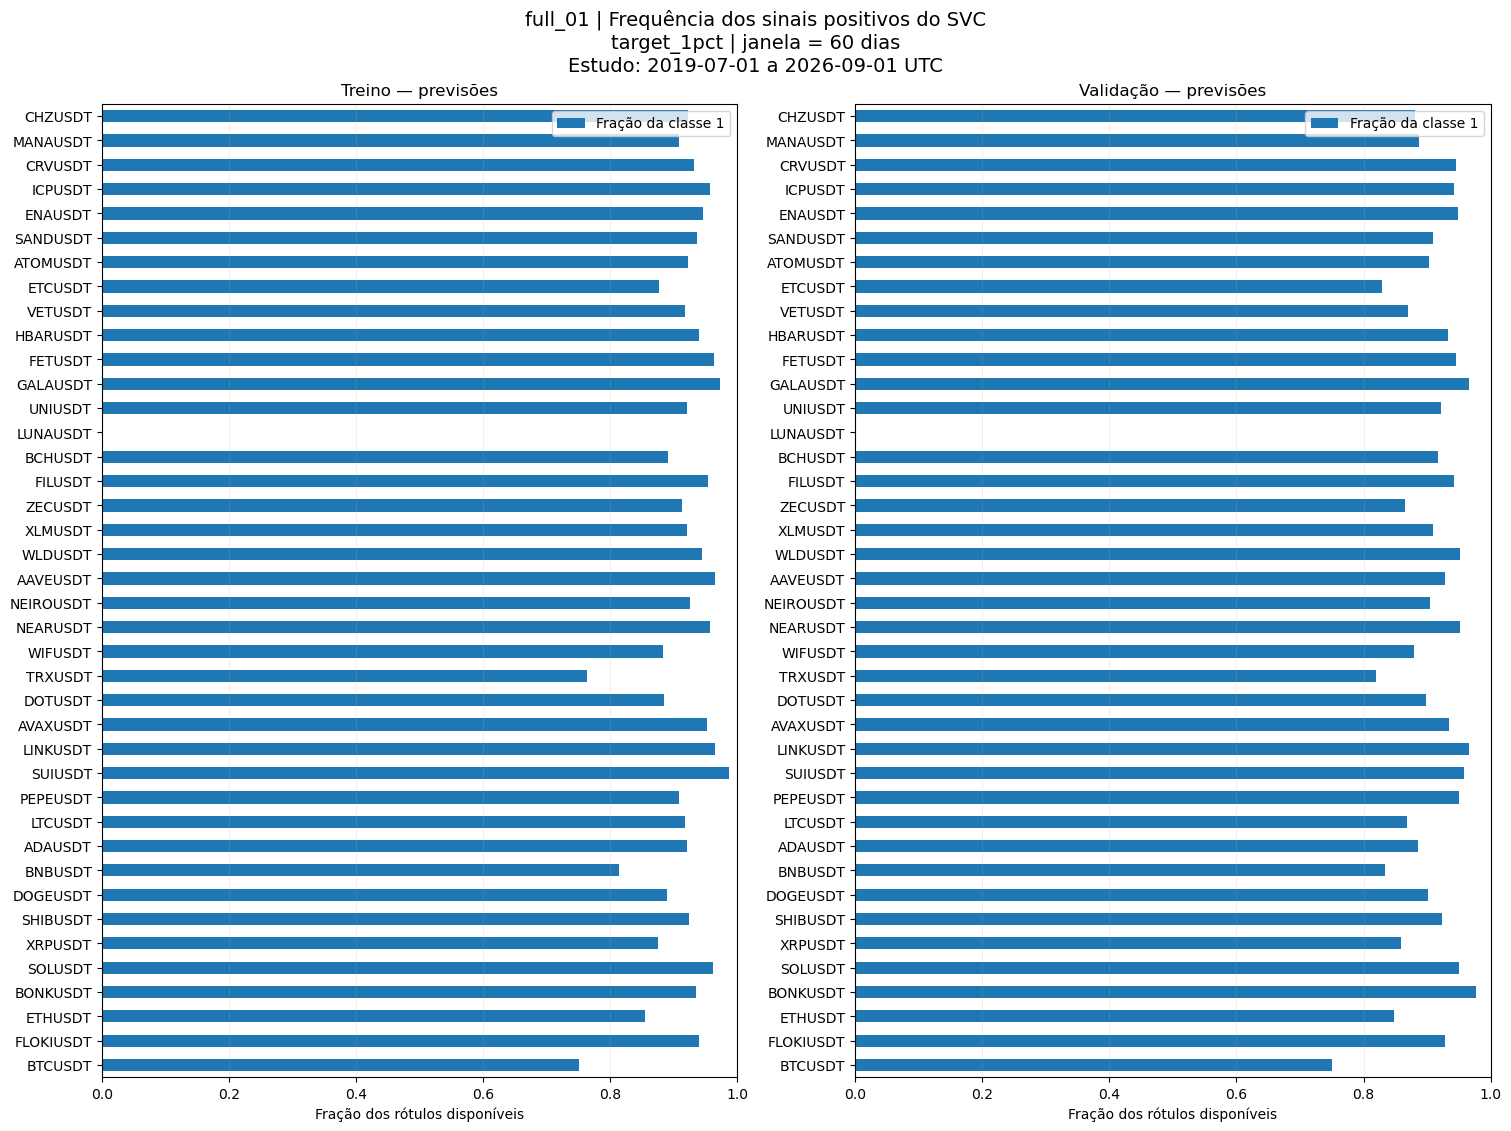

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
for ax, role in zip(axes, roles):
    prefix = "predictions_"
    rows = tables[prefix + role].copy()
    table = rows.drop(columns=["target", "window_size"]).set_index("feature_time_utc")
    bars(
        pd.DataFrame({"Fração da classe 1": table.mean()}),
        ax,
        role_labels[role]
        + (" — previsões" if prefix == "predictions_" else " — observações"),
        "Fração dos rótulos disponíveis",
    )
    ax.set_xlim(0, 1) if len(table.columns) > 15 else ax.set_ylim(0, 1)
fig.suptitle(
    f"{report['run_id']} | Frequência dos sinais positivos do SVC\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Previsões e observações ao longo do tempo

Compare as duas linhas do ativo escolhido: azul representa classe 1, cinza classe 0 e rosa ausência de informação. As datas se referem às variáveis em UTC; os rótulos correspondem ao dia seguinte. A visualização utiliza as datas da matriz salva. Dias isolados podem ser difíceis de distinguir nesta resolução; consulte o CSV para valores exatos.

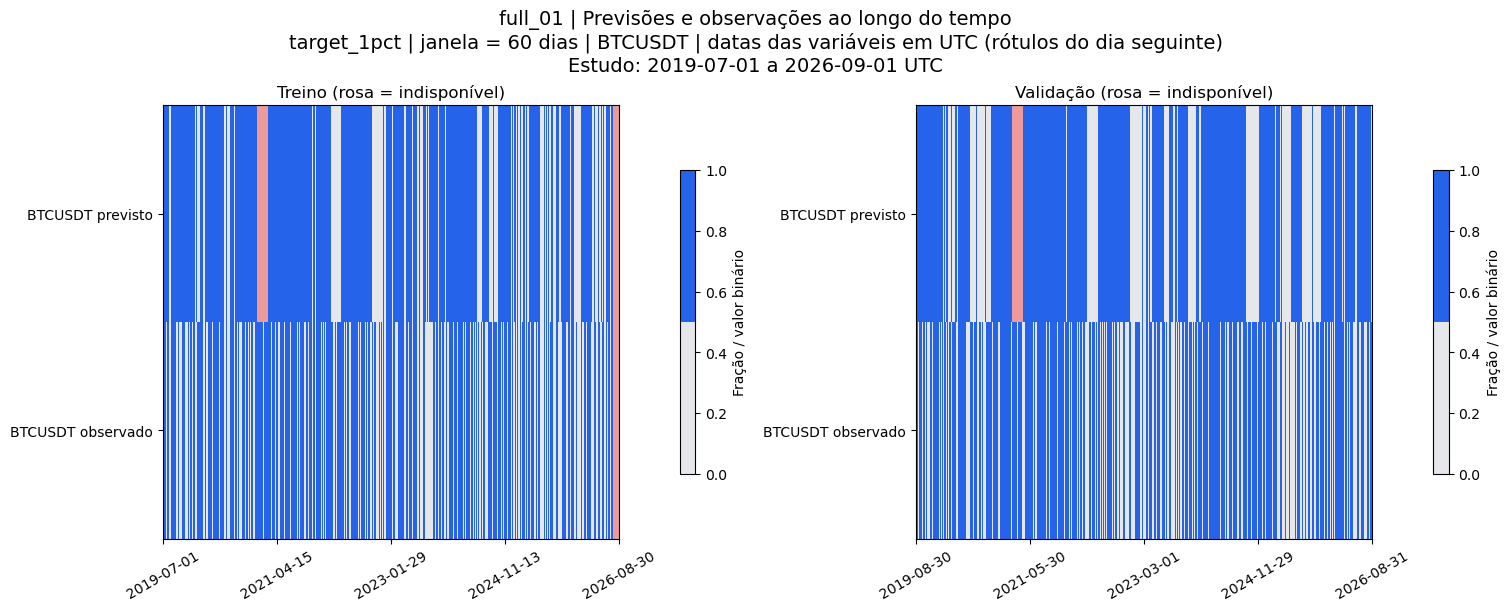

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
for ax, role in zip(axes, roles):
    pred = tables["predictions_" + role].copy()
    actual = tables["actuals_" + role].copy()
    table = (
        pred[["feature_time_utc", symbol]]
        .merge(
            actual[["feature_time_utc", symbol]],
            on="feature_time_utc",
            how="outer",
            suffixes=(" previsto", " observado"),
            validate="one_to_one",
        )
        .sort_values("feature_time_utc")
        .set_index("feature_time_utc")
    )
    heatmap(table.T, ax, role_labels[role] + " (rosa = indisponível)", binary=True)
subtitle += f" | {symbol} | datas das variáveis em UTC (rótulos do dia seguinte)"
fig.suptitle(
    f"{report['run_id']} | Previsões e observações ao longo do tempo\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Variáveis mantidas após o pré-processamento

À esquerda, fração dos ajustes de treino completo que mantiveram cada variável. À direita, os motivos registrados pelos filtros. Frequência de seleção não mede causalidade nem importância da variável para o SVM. As seleções das divisões internas não fazem parte desta tabela consolidada.

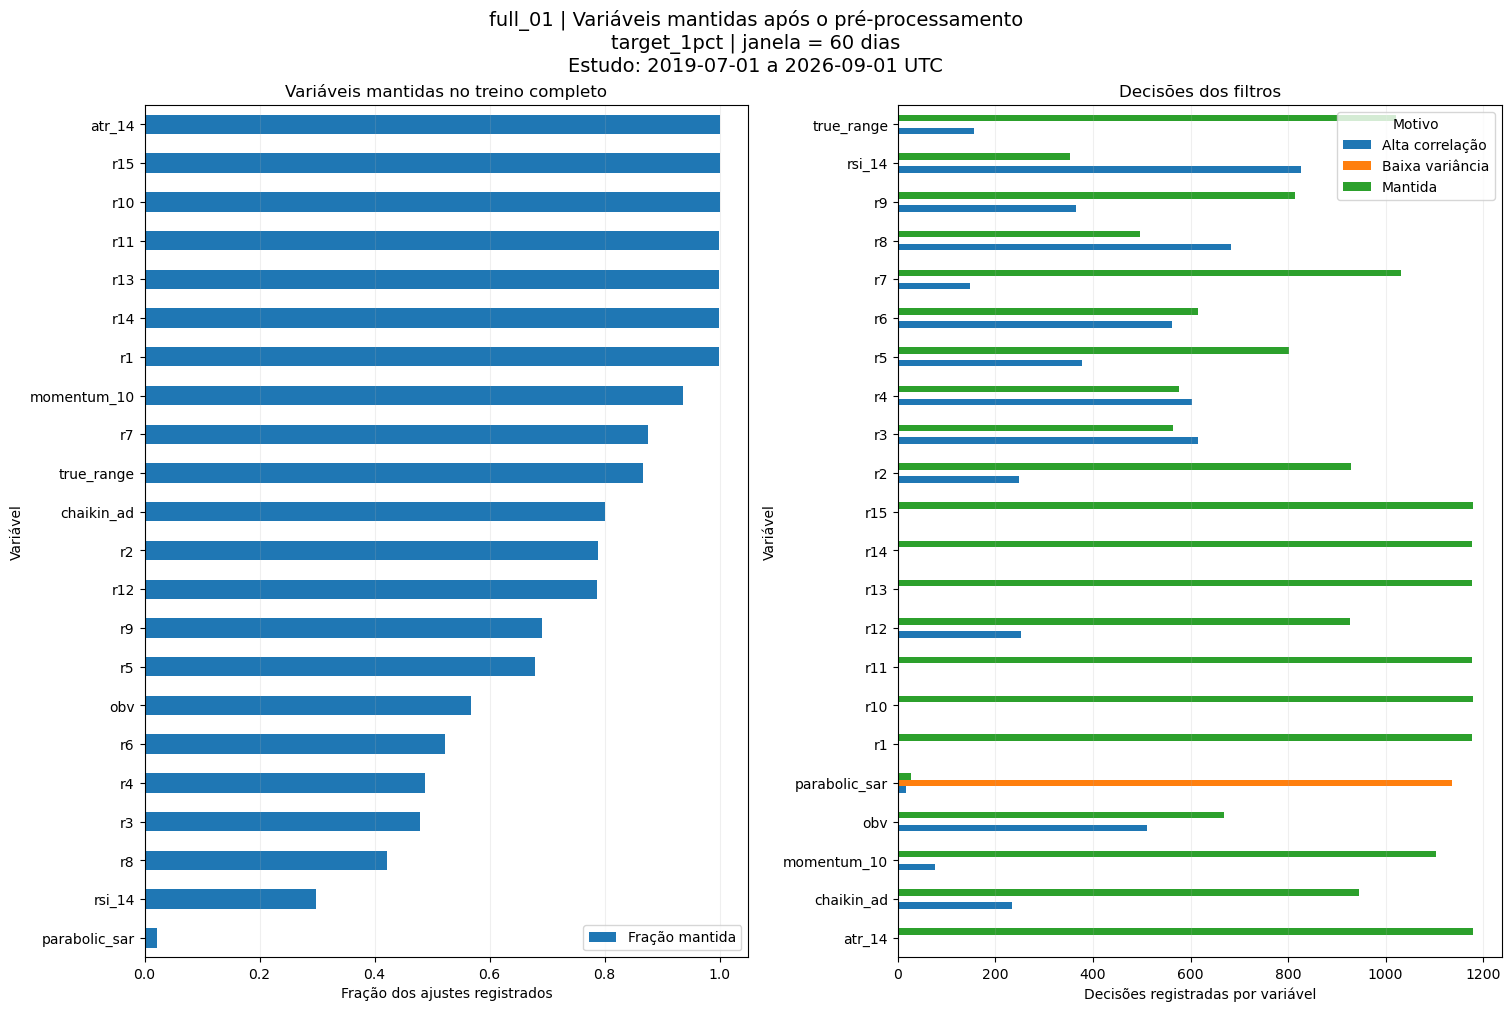

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
rows = tables["feature_selection"].copy()
bars(
    rows.groupby("feature").selected.mean().sort_values().to_frame("Fração mantida"),
    axes[0],
    "Variáveis mantidas no treino completo",
    "Fração dos ajustes registrados",
)
bars(
    pd.crosstab(rows.feature, rows.reason),
    axes[1],
    "Decisões dos filtros",
    "Decisões registradas por variável",
)
fig.suptitle(
    f"{report['run_id']} | Variáveis mantidas após o pré-processamento\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Parâmetros escolhidos pela busca

As contagens de kernels e combinações de C/gamma vêm dos registros de validação do SVC ajustado: um registro por ativo, bloco e configuração. Descrevem escolhas já feitas, sem executar nova busca. Outros parâmetros aparecem na consulta de métricas ao final.

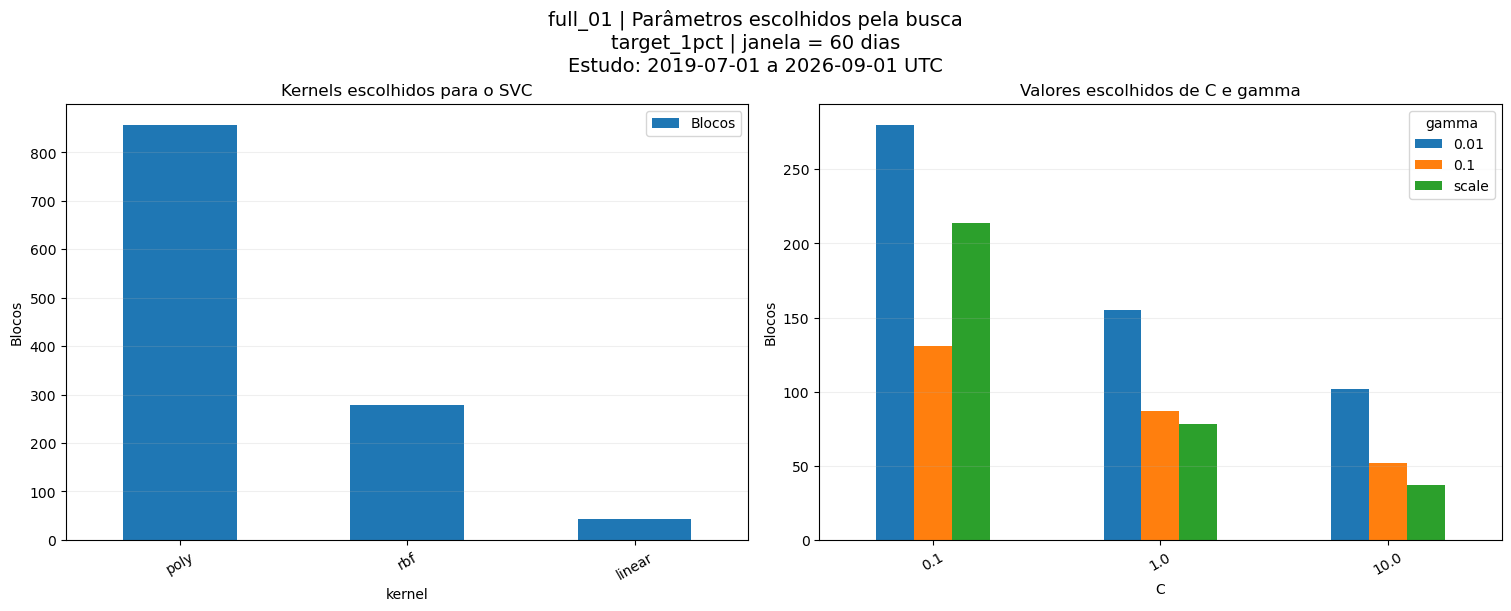

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), layout="constrained")
subtitle = f"{target} | janela = {window_size} dias"
rows = metrics.loc[metrics.role.eq("out_of_sample") & metrics.model.eq("tuned_svc")]
bars(
    rows.kernel.value_counts().to_frame("Blocos"),
    axes[0],
    "Kernels escolhidos para o SVC",
    "Blocos",
)
bars(
    pd.crosstab(rows.C, rows.gamma),
    axes[1],
    "Valores escolhidos de C e gamma",
    "Blocos",
)
fig.suptitle(
    f"{report['run_id']} | Parâmetros escolhidos pela busca\n{subtitle}\nEstudo: {study['start']} a {study['end']} UTC",
    fontsize=14,
)
display(fig)
plt.close(fig)

## Consultar as evidências dos gráficos

As primeiras 20 linhas filtradas incluem contagens, diagnósticos e parâmetros escolhidos. A seleção inclui variância, correlação e detalhes de tratamentos alternativos. As tabelas completas continuam em `report["tables"]`. As colunas técnicas são preservadas para permitir correspondência direta com os CSVs.

In [23]:
display(tables["metrics"].head(20))
display(tables["feature_selection"].head(20))

,role,model,attempted_count,evaluated_count,omitted_count,status,accuracy,precision,recall,f1,...,C,class_weight,coef0,degree,gamma,kernel,symbol,window_size,target,block_id
0,in_sample,tuned_svc,60,60,0,ok,0.800000,0.775510,0.974359,0.863636,...,10.0,<NA>,0.5,4.0,0.01,poly,BTCUSDT,60,target_1pct,0
1,in_sample,default_svc,60,60,0,ok,0.783333,0.750000,1.000000,0.857143,...,NaN,<NA>,NaN,NaN,<NA>,<NA>,BTCUSDT,60,target_1pct,0
2,in_sample,always_negative,60,60,0,ok,0.350000,0.000000,0.000000,0.000000,...,NaN,<NA>,NaN,NaN,<NA>,<NA>,BTCUSDT,60,target_1pct,0
3,in_sample,training_class_frequency,60,60,0,ok,0.650000,0.650000,1.000000,0.787879,...,NaN,<NA>,NaN,NaN,<NA>,<NA>,BTCUSDT,60,target_1pct,0
4,out_of_sample,tuned_svc,60,60,0,ok,0.566667,0.576271,0.971429,0.723404,...,10.0,<NA>,0.5,4.0,0.01,poly,BTCUSDT,60,target_1pct,0
5,out_of_sample,default_svc,60,60,0,ok,0.583333,0.583333,1.000000,0.736842,...,NaN,<NA>,NaN,NaN,<NA>,<NA>,BTCUSDT,60,target_1pct,0
6,out_of_sample,always_negative,60,60,0,ok,0.416667,0.000000,0.000000,0.000000,...,NaN,<NA>,NaN,NaN,<NA>,<NA>,BTCUSDT,60,target_1pct,0
7,out_of_sample,training_class_frequency,60,60,0,ok,0.583333,0.583333,1.000000,0.736842,...,NaN,<NA>,NaN,NaN,<NA>,<NA>,BTCUSDT,60,target_1pct,0
8,in_sample,tuned_svc,60,60,0,ok,0.583333,0.583333,1.000000,0.736842,...,0.1,<NA>,NaN,NaN,scale,rbf,BTCUSDT,60,target_1pct,1
9,in_sample,default_svc,60,60,0,ok,0.783333,0.805556,0.828571,0.816901,...,NaN,<NA>,NaN,NaN,<NA>,<NA>,BTCUSDT,60,target_1pct,1


,feature,position,variance,fallback_sample_variance,selected,reason,related_feature,correlation,fallback_error,symbol,window_size,target,block_id,fit_scope,fold
0,r1,0,1.0,1.016949,True,retained,,NaN,,BTCUSDT,60,target_1pct,0,full_in_sample,-1
1,r2,1,1.0,1.016949,False,high_correlation,r13,0.809339,,BTCUSDT,60,target_1pct,0,full_in_sample,-1
2,r3,2,1.0,1.016949,False,high_correlation,r14,0.810444,,BTCUSDT,60,target_1pct,0,full_in_sample,-1
3,r4,3,1.0,1.016949,True,retained,,NaN,,BTCUSDT,60,target_1pct,0,full_in_sample,-1
4,r5,4,1.0,1.016949,True,retained,,NaN,,BTCUSDT,60,target_1pct,0,full_in_sample,-1
5,r6,5,1.0,1.016949,True,retained,,NaN,,BTCUSDT,60,target_1pct,0,full_in_sample,-1
6,r7,6,1.0,1.016949,True,retained,,NaN,,BTCUSDT,60,target_1pct,0,full_in_sample,-1
7,r8,7,1.0,1.016949,True,retained,,NaN,,BTCUSDT,60,target_1pct,0,full_in_sample,-1
8,r9,8,1.0,1.016949,True,retained,,NaN,,BTCUSDT,60,target_1pct,0,full_in_sample,-1
9,r10,9,1.0,1.016949,True,retained,,NaN,,BTCUSDT,60,target_1pct,0,full_in_sample,-1


## Limites da interpretação

- Compare a validação com os modelos de referência, a distribuição das classes, os resultados ausentes e a cobertura. Desempenho no treino, isoladamente, não demonstra generalização.
- Os gráficos não estabelecem significância estatística nem escolhem uma nova configuração científica.
- Não inferimos retorno, índice de Sharpe, alocação ou resultado de carteiras a partir das métricas de classificação.
- Os CSVs de auditoria por ativo contêm candidatos da busca, divisões internas, normalização e mensagens de falha. Este notebook apresenta os resultados consolidados.
- A revisão científica do Parabolic SAR com parâmetros zero permanece pendente, conforme o [guia de implementação](../docs/decisions/daily-code-organization.md).